In [1]:
from discoveryworld.ActionHistory import ActionType

actionDescriptions = {
    ActionType.PICKUP.name:         {"args": ["arg1"], "desc": "pick up an object (arg1)"},
    ActionType.DROP.name:           {"args": ["arg1"], "desc": "drop an object (arg1)"},
    ActionType.PUT.name:            {"args": ["arg1", "arg2"], "desc": "put an object (arg1) in/on another object (arg2), or give an object (arg1) to another agent (arg2)"},
    ActionType.OPEN.name:           {"args": ["arg1"], "desc": "open an object (arg1)"},
    ActionType.CLOSE.name:          {"args": ["arg1"], "desc": "close an object (arg1)"},
    ActionType.ACTIVATE.name:       {"args": ["arg1"], "desc": "activate an object (arg1)"},
    ActionType.DEACTIVATE.name:     {"args": ["arg1"], "desc": "deactivate an object (arg1)"},
    ActionType.TALK.name:           {"args": ["arg1"], "desc": "talk to another agent (arg1)"},
    ActionType.EAT.name:            {"args": ["arg1"], "desc": "eat an object (arg1)"},
    ActionType.READ.name:           {"args": ["arg1"], "desc": "read an object (arg1)"},
    ActionType.USE.name:            {"args": ["arg1", "arg2"], "desc": "use an object (arg1), e.g. a thermometer, on another object (arg2), e.g. water."},

    ActionType.MOVE_DIRECTION.name:         {"args": ["arg1"], "desc": "move in a specific direction (arg1), which is one of 'north', 'east', 'south', or 'west'."},
    ActionType.ROTATE_DIRECTION.name:       {"args": ["arg1"], "desc": "rotate to face a specific direction (arg1), which is one of 'north', 'east', 'south', or 'west'."},
    ActionType.TELEPORT_TO_LOCATION.name:   {"args": ["arg1"], "desc": "teleport to a specific location (arg1), by name. A list of valid teleport locations is provided elsewhere."},
    ActionType.TELEPORT_TO_OBJECT.name:     {"args": ["arg1"], "desc": "teleport beside a specific object (arg1). 'arg1' should be the UUID of the object to teleport to."},

    ActionType.DISCOVERY_FEED_GET_UPDATES.name:     {"args": [], "desc": "read the latest status updates on discovery feed"},
    ActionType.DISCOVERY_FEED_GET_POST_BY_ID.name:  {"args": ["arg1"], "desc": "read a specific post on discovery feed (arg1). 'arg1' should be the integer ID of the post."},
}

## View this notebook's run in the DiscoveryWorld UI

Run the setup and action cells above, then run the cell below. It refreshes the observation and displays the full game UI (world, inventory, task information and action message). It does not perform an action or advance the world. Run it again after each action and `api.tick()` to see the result.

The API uses an offscreen Pygame window, so no desktop game window appears. Screenshots are saved in `api.FRAME_DIR`; frames are captured by `getAgentObservation()`, not by `tick()` alone. The `vision` images contain only the world viewport; the numbered frame below includes the full UI.

For a separate, keyboard-controlled game, run this in a terminal from the project root:

```powershell
uv run python environment/discoveryworld/scripts/userstudy.py --scenario combinatorial_chemistry_easy --seed 0
```

That starts a fresh game with the same scenario and seed; it does not attach to this notebook's in-memory world. Press Tab for task information and F1 for controls.

The saved notebook run only read the Discovery Feed once, so there may be no visible world change. Before choosing another random action, refresh `observation` and rebuild `accessibleObjects` from its inventory and accessible environment objects. Otherwise those variables describe an earlier state. Use a unique `threadID` for a new run if you want to preserve earlier screenshots.


In [2]:
from langchain_openai import ChatOpenAI
from dotenv import load_dotenv

load_dotenv()

model = ChatOpenAI(
        model="gpt-6-luna",
        reasoning_effort="medium",
        max_retries=3,
        timeout=60,
    )

In [3]:
from pydantic import BaseModel, Field

class ActionResponse(BaseModel):
    """An action and its arguments for the DiscoveryWorld agent."""

    action: str = Field(description="Name of the action to perform")
    arg1: int | str | None = Field(description="First argument, or null if unused")
    arg2: int | str | None = Field(description="Second argument, or null if unused")

class DialogResponse(BaseModel):
    """An option selected from the current dialog."""
    chosen_dialog_option_int: int = Field(description="Number of the dialog option to select")


def submitLLMPrompt(prompt: str, in_dialog: bool = False) -> dict:
    schema = DialogResponse if in_dialog else ActionResponse
    response = model.with_structured_output(schema).invoke(prompt)
    return response.model_dump(mode="json")


In [4]:
import json
import time
from pathlib import Path
from IPython.display import Image, display
from discoveryworld.DiscoveryWorldAPI import DiscoveryWorldAPI


def navigation_loop_detected(actions_taken, window=6):
    """Detect repeated positions during travel with unchanged inventory."""
    recent = actions_taken[-window:]
    navigation = {"MOVE_DIRECTION", "ROTATE_DIRECTION", "TELEPORT_TO_OBJECT", "TELEPORT_TO_LOCATION"}
    if len(recent) < window or any(r["action"].get("action") not in navigation for r in recent):
        return False
    inventories = [json.dumps(r.get("inventory", []), sort_keys=True) for r in recent]
    positions = [(r["location"]["x"], r["location"]["y"]) for r in recent]
    return len(set(inventories)) == 1 and len(set(positions)) <= window // 2


def agent_step(api, observation, actions_taken):
    """Choose one action using the current state and previous outcomes."""
    prompt = (
        "You are a DiscoveryWorld agent. Complete the task described in the observation.\n"
        "Choose one action at a time and check its outcome before continuing.\n"
        "Teleporting moves only you, not the target object. Pick up movable objects "
        "before taking them elsewhere. Both arguments of USE must be accessible "
        "simultaneously (in inventoryObjects or accessibleEnvironmentObjects).\n"
        "After reaching an object, perform the needed interaction before leaving. "
        "Use directions_you_can_move for movement; rotate to face nearby objects.\n"
        "Review your history. Avoid repeating travel without task progress. "
        "If travel repeats, identify the missing interaction or prerequisite.\n"
        "For chemical experiments, keep track of chemicals tried and outcomes; "
        "follow the task's instructions for cleaning the jar between trials.\n"
        "Use only supplied UUIDs and valid actions. Use null for unused arguments.\n"
    )
    prompt += "Current observation:\n" + json.dumps(observation["ui"], indent=2)
    prompt += "\nAvailable actions:\n" + json.dumps(api.listKnownActions(limited=False), indent=2)
    prompt += "\nTeleport locations:\n" + json.dumps(api.listTeleportLocationsDict(), indent=2)
    prompt += "\nAction history (including outcomes):\n" + json.dumps(actions_taken, indent=2)
    if navigation_loop_detected(actions_taken):
        prompt += (
            "\nLOOP DETECTED: Recent navigation revisits the same positions with "
            "unchanged inventory. Identify the missing prerequisite. Prefer an "
            "accessible interaction that advances the task; collect needed movable "
            "objects before leaving. Do not repeat the same travel cycle."
        )
    in_dialog = api.isAgentInDialog(agentIdx=0)
    if in_dialog:
        prompt += (
            "\nYou are in dialog. Select a listed option from dialog_box and return "
            "chosen_dialog_option_int instead of an ordinary action."
        )
    return submitLLMPrompt(prompt, in_dialog=in_dialog)


def exampleLoop(scenarioName, difficultyStr, randomSeed, maxSteps=20):
    """Run the agent and return its world and history for inspection."""
    # Preserve screenshots from earlier runs.
    api = DiscoveryWorldAPI(threadID=time.time_ns())
    if not api.loadScenario(scenarioName=scenarioName, difficultyStr=difficultyStr,
                            randomSeed=randomSeed, numUserAgents=1):
        raise RuntimeError(f"Could not load {scenarioName} ({difficultyStr})")

    return continueLoop(api, [], maxSteps=maxSteps)


def continueLoop(api, actions_taken, maxSteps=20):
    """Take more actions in the existing world, preserving history and numbering.

    This calls the model once per action. It does not reload the scenario.
    The supplied history is updated in place, including if a later call fails.
    """
    observation = api.getAgentObservation(agentIdx=0)
    start_step = actions_taken[-1]["step"] + 1 if actions_taken else 0
    for step in range(start_step, start_step + maxSteps):
        if observation.get("errors"):
            raise RuntimeError(observation["errors"])
        if api.areTasksComplete():
            break
        if navigation_loop_detected(actions_taken):
            print("Repeated travel detected; requesting a different plan.")
        action = agent_step(api, observation, actions_taken)
        # The API may mutate its input while resolving UUIDs; pass a copy.
        result = api.performAgentAction(agentIdx=0, actionJSON=action.copy())
        tick_result = api.tick()
        if not tick_result.get("success"):
            raise RuntimeError(tick_result)
        observation = api.getAgentObservation(agentIdx=0)
        actions_taken.append({
            "step": step,
            "action": action,
            "result": result,
            "message": observation["ui"].get("lastActionMessage", ""),
            "location": observation["ui"]["agentLocation"],
            "inventory": observation["ui"]["inventoryObjects"],
        })
        print(f"Step {step}: {json.dumps(action)}")
        print(actions_taken[-1]["message"])
        print("Success:", result.get("success"))

    print("Scorecard:", json.dumps(api.getTaskScorecard(), indent=2))
    # Show the same world the LLM just acted in, including the final action.
    frame = Path(api.FRAME_DIR) / f"ui_agent_0_frame_{api.getStepCounter()}.png"
    display(Image(data=frame.read_bytes(), width=960))
    return api, actions_taken


pygame 2.6.1 (SDL 2.28.4, Python 3.13.9)
Hello from the pygame community. https://www.pygame.org/contribute.html


Loading sprites from index file: C:\dev\AI\Dundalk\advanced_agentic\project_code\environment\discoveryworld\discoveryworld\assets\spriteIndex.json
	Loaded 36 sprites from pixymoon/CuteRPG_Interior/32x32/CuteRPG_Interior_custom.png.
	Loaded 22 sprites from pixymoon/CuteRPG_Houses/32x32/CuteRPG_Houses_A-modified1.png.
	Loaded 30 sprites from pixymoon/CuteRPG_Desert/32x32/CuteRPG_Desert_Outside_modified.png.
	Loaded 1 sprites from pixymoon/CuteRPG_Desert/32x32/CuteRPG_Desert_Inside.png.
	Loaded 9 sprites from pixymoon/CuteRPG_Village/32x32/CuteRPG_Village_House.png.
	Loaded 9 sprites from pixymoon/CuteRPG_Houses/32x32/CuteRPG_Houses_C.png.
	Loaded 25 sprites from placeholder/instruments2.png.
	Loaded 46 sprites from pixymoon/CuteRPG_Forest/32x32/CuteRPG_Forest_modified2.png.
	Loaded 22 sprites from pixymoon/CuteRPG_Village/32x32/CuteRPG_Village.png.
	Loaded 14 sprites from pixymoon/CuteRPG_Caves/32x32/CuteRPG_Caves.png.
	Loaded 24 sprites from pixymoon/CuteRPG_Castle_New/32x32/CuteRPG_Cas

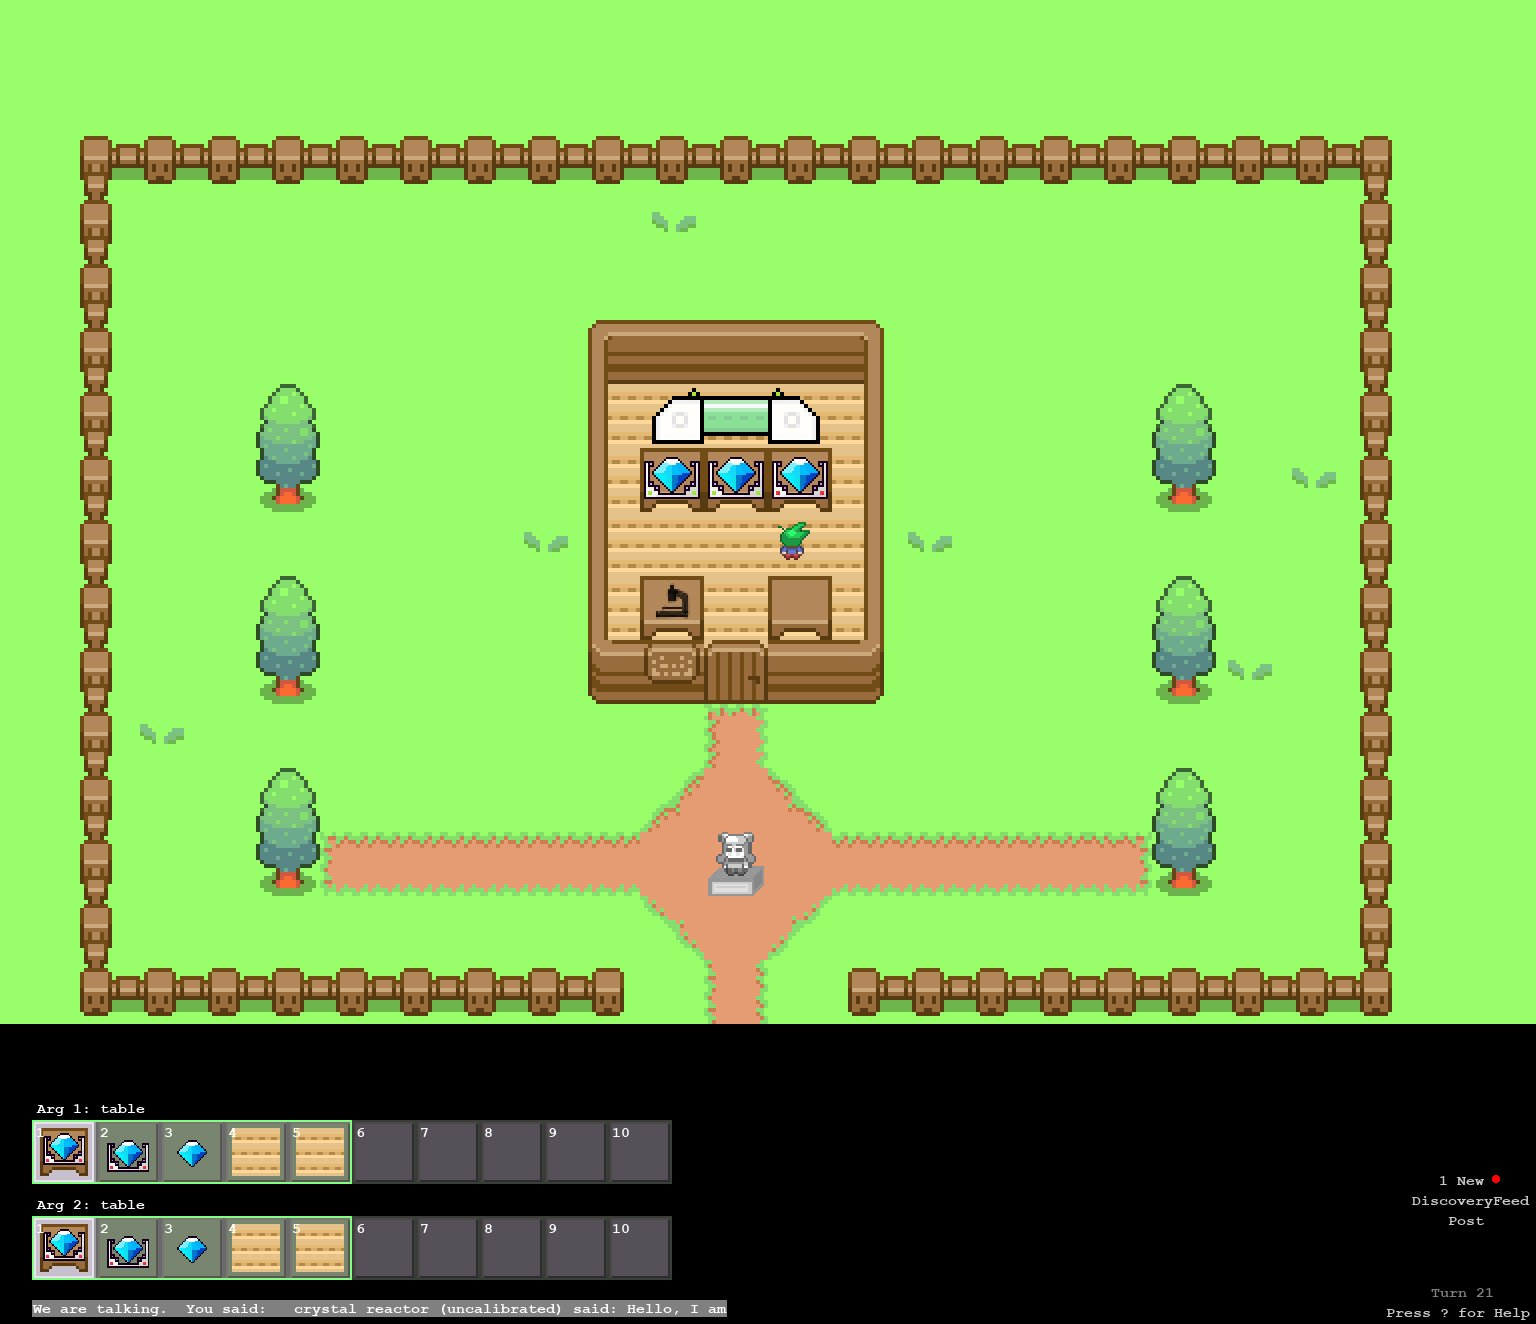

In [5]:
# Run this cell after the model, schema and function definition cells.
# The returned api is the agent's actual world, usable by the UI display cell.
api, actions_taken = exampleLoop(
    scenarioName="Reactor Lab",
    difficultyStr="Easy",
    randomSeed=0,
    maxSteps=20,
)


## Continue the existing run
Rerun the function definitions cell above, then run the next cell to take up to 20 more actions in the current world. Do not rerun the fresh-run cell unless you want to reset the scenario. This uses the existing `api` and `actions_taken` in the kernel and makes model calls. If the kernel was restarted, the live world is gone; start a fresh run first.


### IS IN DIALOG
Saving world history...
Number of items in world history:22
Size of most recent item: 19043 bytes 18.5966796875 KB
World history includes 1155 objects.
World history saved in 0.019985675811767578 seconds.
Step 20: {"chosen_dialog_option_int": 9}
We are talking.  You said: Exit

crystal reactor (uncalibrated) said: Exiting crystal reactor controls.
Success: True
Saving world history...
Number of items in world history:23
Size of most recent item: 19048 bytes 18.6015625 KB
World history includes 1155 objects.
World history saved in 0.019234418869018555 seconds.
Step 21: {"action": "USE", "arg1": 33120, "arg2": 24678}
We are talking.  You said: 

crystal reactor (uncalibrated) said: Hello, I am Crystal Reactor #3.
The current resonance frequence is: 5710 Hertz.
The allowable range is 0 to 10,000 Hz.
Success: True
### IS IN DIALOG
Saving world history...
Number of items in world history:24
Size of most recent item: 19052 bytes 18.60546875 KB
World history includes 1155 obj

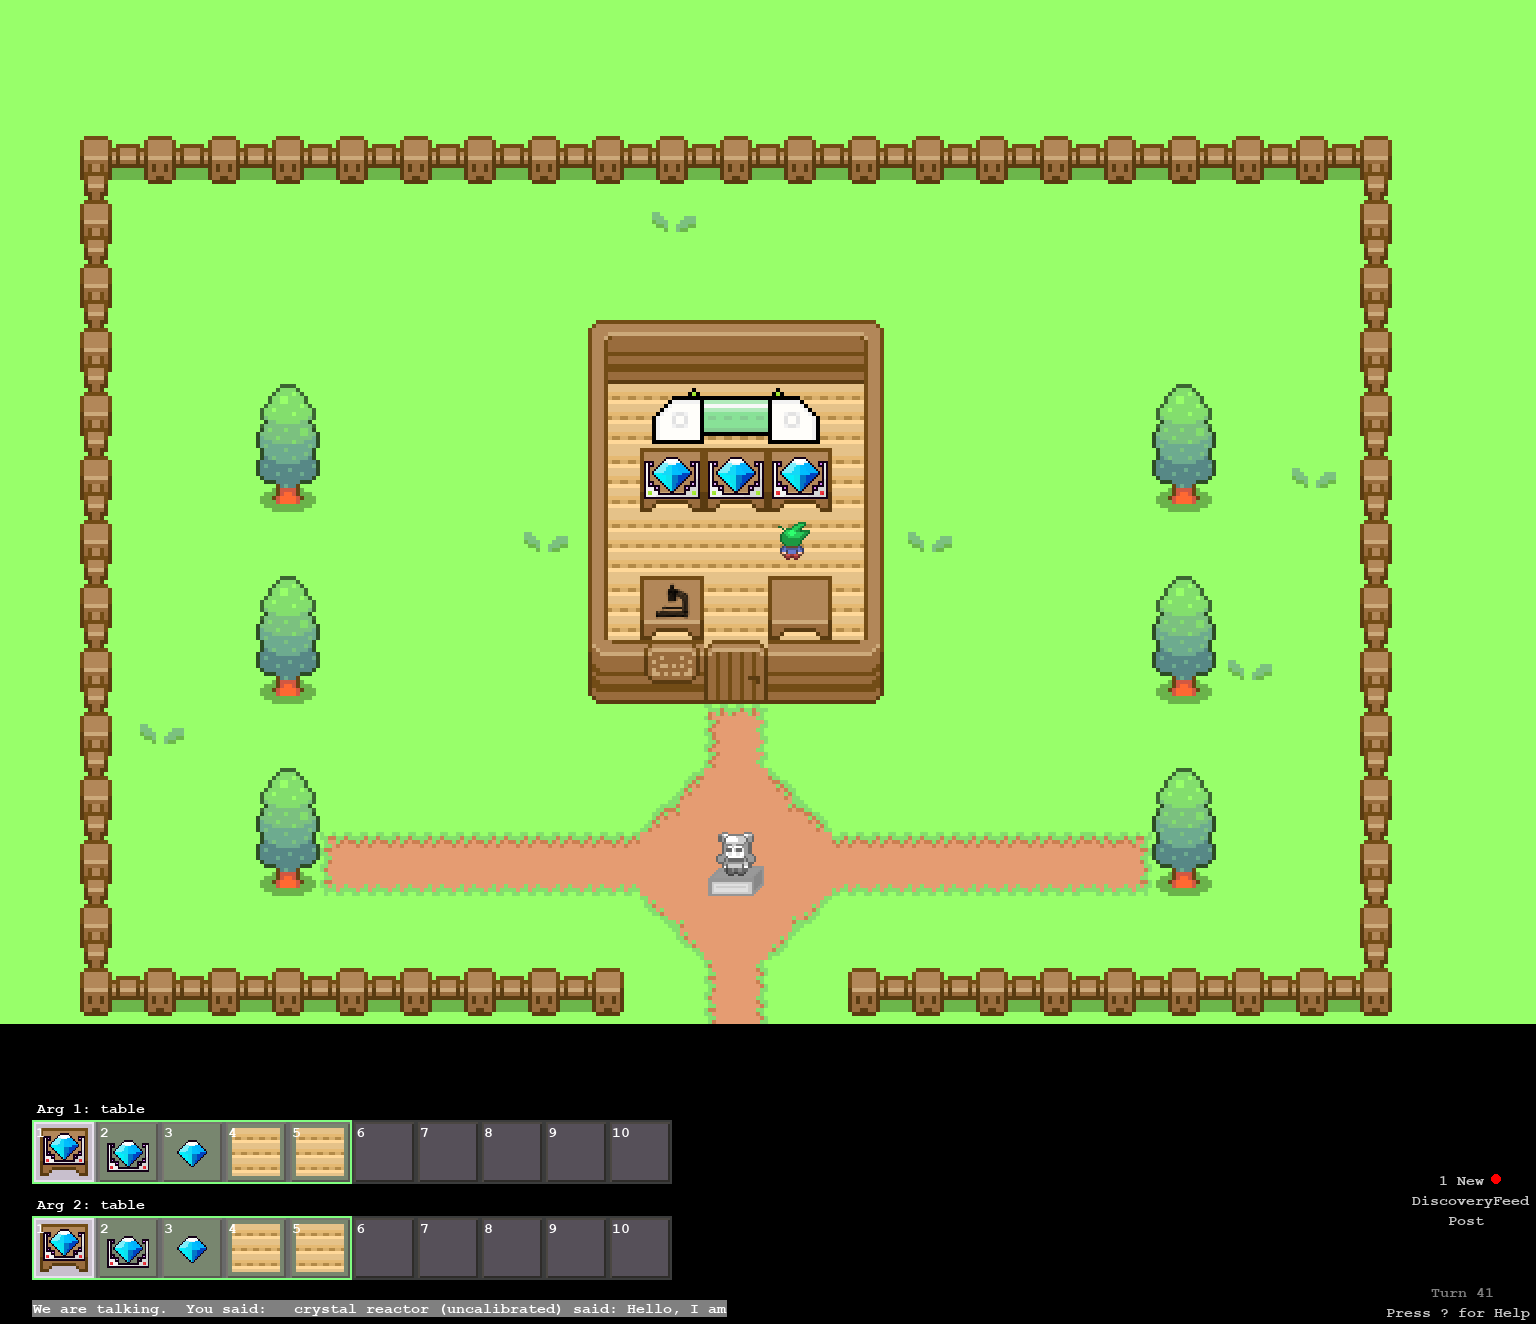

In [6]:
api, actions_taken = continueLoop(api, actions_taken, maxSteps=20)


### IS IN DIALOG
Saving world history...
Number of items in world history:42
Size of most recent item: 19157 bytes 18.7080078125 KB
World history includes 1155 objects.
World history saved in 0.019661903381347656 seconds.
Step 40: {"chosen_dialog_option_int": 9}
We are talking.  You said: Exit

crystal reactor (uncalibrated) said: Exiting crystal reactor controls.
Success: True
Saving world history...
Number of items in world history:43
Size of most recent item: 19167 bytes 18.7177734375 KB
World history includes 1155 objects.
World history saved in 0.02169656753540039 seconds.
Step 41: {"action": "USE", "arg1": 33120, "arg2": 24678}
We are talking.  You said: 

crystal reactor (uncalibrated) said: Hello, I am Crystal Reactor #3.
The current resonance frequence is: 5710 Hertz.
The allowable range is 0 to 10,000 Hz.
Success: True
### IS IN DIALOG
Saving world history...
Number of items in world history:44
Size of most recent item: 19167 bytes 18.7177734375 KB
World history includes 1155

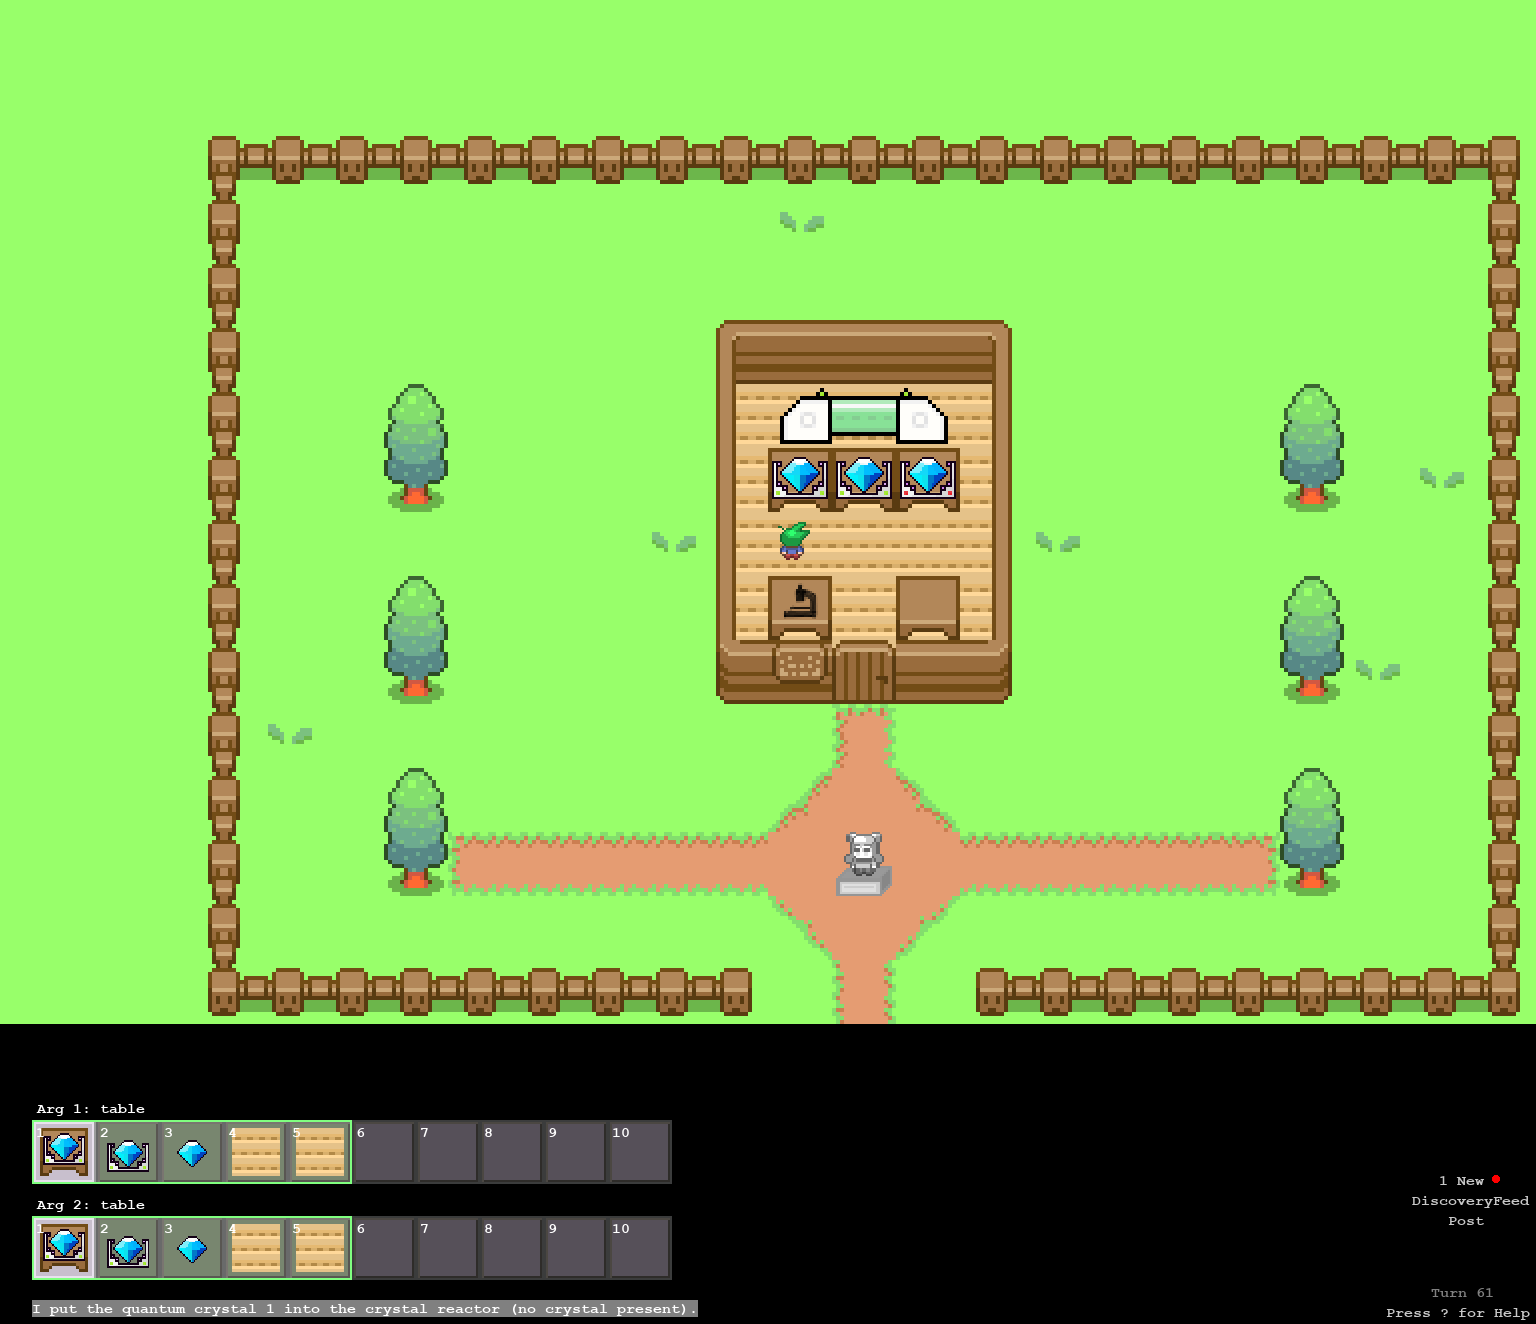

In [7]:
api, actions_taken = continueLoop(api, actions_taken, maxSteps=20)